# 06 · Model comparison

Compare the majority-class baseline, two logistic regression configurations and six constrained decision trees. Recompute every result on the same training folds.

## Load and split data

In [6]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

root = Path.cwd()
if not (root / "data").is_dir():
    root = root.parent

df = pd.read_csv(root / "data/raw/online_shoppers_intention.csv").drop_duplicates()
X = df.drop(columns="Revenue")
X["Weekend"] = X["Weekend"].astype(int)
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Preprocessing

Keep the same features, scaling and encoding as notebook 04. Trees do not require scaling, but retaining the pipeline keeps preparation consistent. Preprocessing is fitted separately within each training fold.

In [7]:
numeric_features = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
categorical_features = [
    "Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType",
]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("weekend", "passthrough", ["Weekend"]),
])

## Training cross-validation

Use the same five stratified folds and purchase-class metrics as earlier notebooks. Tables show fold mean ± standard deviation.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train, y_train))

scoring = {
    "f1": make_scorer(f1_score, pos_label=True, zero_division=0),
    "precision": make_scorer(precision_score, pos_label=True, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=True, zero_division=0),
    "accuracy": "accuracy",
}


## Candidate settings

Try tree depths 3, 5 and 8, each with default and balanced class weights: six configurations in total. Set `min_samples_leaf=20` to avoid very small leaves and constrain depth to limit overfitting. Fix `random_state=42`; leave other tree settings at their defaults. Logistic regression retains the settings from notebook 04. No threshold tuning is performed.

In [9]:
candidates = [("Dummy", DummyClassifier(strategy="most_frequent"))]
for weight in [None, "balanced"]:
    candidates.append(("Logistic regression", LogisticRegression(
        class_weight=weight, C=1.0, solver="lbfgs", max_iter=2000
    )))
for depth in [3, 5, 8]:
    for weight in [None, "balanced"]:
        candidates.append(("Decision tree", DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=20,
            class_weight=weight, random_state=42,
        )))

## Model comparison

Select each learned model by highest mean purchase-class F1. Prefer the shallower tree if F1 ties. The selected column marks the chosen configuration in each learned family. All rows use identical folds; baseline scores are recomputed here.

In [10]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for family, estimator in candidates:
        model = Pipeline([
            ("preprocessing", preprocessor),
            ("model", estimator),
        ])
        scores = cross_validate(
            model, X_train, y_train, cv=cv_folds, scoring=scoring,
            error_score="raise",
        )
        params = estimator.get_params()
        row = {
            "model": family,
            "class_weight": str(params.get("class_weight")),
            "max_depth": params.get("max_depth"),
            "settings": (
                "strategy=most_frequent" if family == "Dummy" else
                "C=1.0, solver=lbfgs, max_iter=2000" if family == "Logistic regression"
                else "min_samples_leaf=20, random_state=42"
            ),
        }
        for metric in scoring:
            row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
            row[f"{metric}_std"] = scores[f"test_{metric}"].std()
        rows.append(row)

results = pd.DataFrame(rows)
selected_indices = []
for family in ["Logistic regression", "Decision tree"]:
    ranked = results[results["model"] == family].sort_values(
        ["f1_mean", "max_depth"], ascending=[False, True], kind="stable"
    )
    selected_indices.append(ranked.index[0])
results["selected"] = results.index.isin(selected_indices)
best_index = results.loc[selected_indices, "f1_mean"].idxmax()

comparison = results[["model", "class_weight", "max_depth", "settings", "selected"]].copy()
comparison["max_depth"] = comparison["max_depth"].astype("Int64").astype("string").fillna("-")
for metric in scoring:
    comparison[metric] = [
        f"{mean:.2%} ± {std:.2%}"
        for mean, std in zip(results[f"{metric}_mean"], results[f"{metric}_std"])
    ]
display(comparison)
print("Current best configuration:")
print(comparison.loc[best_index].to_string())

assert len(results) == 9
assert results["selected"].sum() == 2
assert results.loc[results["model"] == "Dummy", "f1_mean"].eq(0).all()

,model,class_weight,max_depth,settings,selected,f1,precision,recall,accuracy
0,Dummy,None,-,strategy=most_frequent,False,0.00% ± 0.00%,0.00% ± 0.00%,0.00% ± 0.00%,84.37% ± 0.02%
1,Logistic regression,None,-,"C=1.0, solver=lbfgs, max_iter=2000",False,49.45% ± 2.77%,74.15% ± 3.03%,37.15% ± 2.75%,88.15% ± 0.48%
2,Logistic regression,balanced,-,"C=1.0, solver=lbfgs, max_iter=2000",True,60.63% ± 2.44%,50.80% ± 2.35%,75.23% ± 2.85%,84.72% ± 1.10%
3,Decision tree,None,3,"min_samples_leaf=20, random_state=42",False,61.65% ± 5.77%,69.26% ± 4.04%,55.83% ± 7.30%,89.25% ± 1.19%
4,Decision tree,balanced,3,"min_samples_leaf=20, random_state=42",False,63.06% ± 1.04%,49.75% ± 1.40%,86.17% ± 1.84%,84.21% ± 0.77%
5,Decision tree,None,5,"min_samples_leaf=20, random_state=42",True,64.43% ± 3.77%,72.63% ± 2.70%,58.06% ± 5.14%,90.02% ± 0.82%
6,Decision tree,balanced,5,"min_samples_leaf=20, random_state=42",False,62.58% ± 1.07%,49.80% ± 1.50%,84.27% ± 1.87%,84.24% ± 0.75%
7,Decision tree,None,8,"min_samples_leaf=20, random_state=42",False,63.26% ± 1.82%,68.87% ± 2.02%,58.52% ± 1.89%,89.38% ± 0.54%
8,Decision tree,balanced,8,"min_samples_leaf=20, random_state=42",False,61.88% ± 0.94%,49.45% ± 1.50%,82.83% ± 2.94%,84.04% ± 0.81%


Current best configuration:
model                                  Decision tree
class_weight                                    None
max_depth                                          5
settings        min_samples_leaf=20, random_state=42
selected                                        True
f1                                    64.43% ± 3.77%
precision                             72.63% ± 2.70%
recall                                58.06% ± 5.14%
accuracy                              90.02% ± 0.82%


## Findings

The current best configuration is a decision tree with `max_depth=5`, `min_samples_leaf=20` and default class weights. Its mean purchase F1 is 64.43% (standard deviation 3.77%), compared with 60.63% (2.44%) for balanced logistic regression and 0% for the majority-class baseline.

The selected tree has higher precision than balanced logistic regression (72.63% versus 50.80%) but lower recall (58.06% versus 75.23%). Balanced tree weights increase recall, but the resulting loss of precision means none beats the selected tree on F1. Increasing depth to 8 does not improve mean F1.

## Out-of-fold error analysis

Predict each training session using a model fitted on the other four folds.

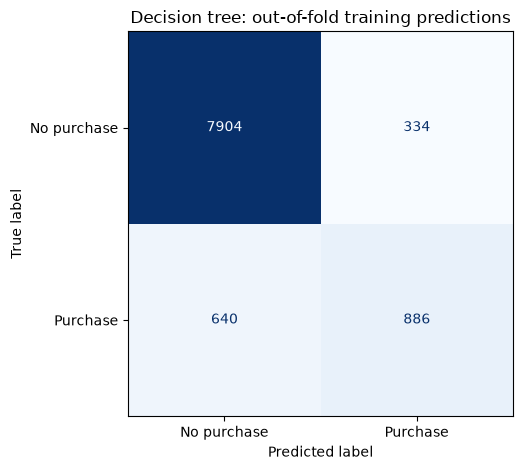

Correct non-purchases    7904
False positives           334
False negatives           640
Correct purchases         886
dtype: int64

In [11]:
best_family, best_estimator = candidates[best_index]
best_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", best_estimator),
])
oof_predictions = cross_val_predict(
    best_model, X_train, y_train, cv=cv_folds, method="predict"
)
cm = confusion_matrix(y_train, oof_predictions, labels=[False, True])
ConfusionMatrixDisplay(
    cm, display_labels=["No purchase", "Purchase"]
).plot(cmap="Blues", values_format="d", colorbar=False)
plt.title(f"{best_family}: out-of-fold training predictions")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
error_summary = pd.Series({
    "Correct non-purchases": tn,
    "False positives": fp,
    "False negatives": fn,
    "Correct purchases": tp,
})
display(error_summary)
assert cm.sum() == len(y_train)

## Misclassified sessions

A false positive predicts a purchase that did not happen. A false negative misses a purchase that did happen.

In [12]:
errors = X_train.copy()
errors["actual_purchase"] = y_train
errors["predicted_purchase"] = oof_predictions
false_positives = errors[~errors["actual_purchase"] & errors["predicted_purchase"]]
false_negatives = errors[errors["actual_purchase"] & ~errors["predicted_purchase"]]
example_columns = [
    "PageValues", "ProductRelated", "ExitRates", "VisitorType",
    "actual_purchase", "predicted_purchase",
]
display(pd.concat({
    "False positive": false_positives.head(3),
    "False negative": false_negatives.head(3),
}, names=["error", "row"])[example_columns])
print(f"Missed purchases: {fn} of {fn + tp} ({fn / (fn + tp):.2%})")
print(f"False purchase predictions: {fp} of {fp + tp} ({fp / (fp + tp):.2%})")
assert len(false_positives) == fp and len(false_negatives) == fn

PageValues  ProductRelated  ExitRates  \
error          row                                            
False positive 4950     1.036091              61   0.013348   
               10360    5.552517              58   0.005582   
               8879    62.330356              32   0.001016   
False negative 11124    0.000000             107   0.013147   
               9166     0.000000               0   0.066667   
               7700     0.000000              16   0.068750   

                            VisitorType  actual_purchase  predicted_purchase  
error          row                                                            
False positive 4950   Returning_Visitor            False                True  
               10360  Returning_Visitor            False                True  
               8879         New_Visitor            False                True  
False negative 11124  Returning_Visitor             True               False  
               9166         New_Visitor             True               False  
               7700   Returning_Visitor             True               False

Missed purchases: 640 of 1526 (41.94%)
False purchase predictions: 334 of 1220 (27.38%)


## Draft Conclusion

The depth-5 decision tree with min_samples_leaf=20 and default class weights performed best in this comparison. Its mean purchase-class F1 was 64.43%, compared with 60.63% for balanced logistic regression and 0% for the majority-class baseline. However, its scores varied more across folds: the standard deviation was 3.77 percentage points, compared with 2.44 for logistic regression. The tree is the strongest candidate so far, but this does not guarantee better performance on new data.

Its main weakness was missing purchases. Across the out-of-fold predictions, it missed 640 of 1,526 purchases (41.94%) and made 334 incorrect purchase predictions (27.38% of all predicted purchases). It was much better at identifying non-purchases, correctly classifying 7,904 of 8,238. This helps explain why its mean accuracy of 90.02% gives an incomplete picture of performance. These counts combine predictions across folds, while the comparison table reports average fold scores.

All three displayed missed purchases had zero PageValues. This is worth investigating, although three examples are too few to establish a pattern. Compared with balanced logistic regression, the tree made more precise purchase predictions but missed a larger share of actual purchases.

The results are limited to this historical dataset and may not carry over to other shops or future shoppers. Before using the model for real-time predictions, the availability of session features, particularly PageValues, would need checking. The predictions also do not explain why someone makes a purchase.

The model settings and error analysis used the same training folds, so these are development results. The held-out test set remains unused. After considering checkpoint feedback, the next step is to finalise the model and evaluation choices, then evaluate once on the test set.
